# DAY2 실습 05 : Steel 전력 데이터

부하 유형·요일·평일과 주말로 집단을 나누어 기술통계, 비율, 순위를 구한다.
문제 아래 코드 셀에 직접 코드를 작성하고 실행해 본다.

데이터 파일 : `Steel_industry_data.csv`
출처 : UCI Machine Learning Repository - [Steel Industry Energy Consumption](https://archive.ics.uci.edu/dataset/851/steel+industry+energy+consumption)

철강 공장의 2018년 1년치 전력 사용 기록이다. 15분마다 한 번씩 기록되어 총 35,040행이고, 한 줄이 15분 한 구간이다.

| 컬럼 | 설명 |
|---|---|
| Usage_kWh | 15분 구간의 전력 사용량 (kWh) |
| Lagging_Current_Reactive.Power_kVarh | 지상 무효전력 (kVarh) |
| Leading_Current_Reactive_Power_kVarh | 진상 무효전력 (kVarh) |
| CO2(tCO2) | 탄소배출량 |
| Lagging_Current_Power_Factor | 지상 역률 (%) |
| Leading_Current_Power_Factor | 진상 역률 (%) |
| WeekStatus | 평일(Weekday) / 주말(Weekend) |
| Day_of_week | 요일 |
| Load_Type | 부하 유형 (Light_Load / Medium_Load / Maximum_Load) |

In [ ]:
%pip install -q koreanize-matplotlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import koreanize_matplotlib

In [ ]:
import os

from google.colab import drive

drive.mount("/content/drive")
data_folder = "/content/drive/MyDrive/HD-AI/data"
csv_path = os.path.join(data_folder, "Steel_industry_data.csv")

df = pd.read_csv(csv_path)

data = df.copy()

### 1. `groupby` / `agg` : 부하 유형별 요약표

상황 : 부하 유형별로 전력 사용 수준과 퍼짐을 한 표로 정리해 보고하려 한다.

`Load_Type`별 `Usage_kWh`의 n, 합계, 평균, 중앙값, 표준편차를 한 표로 만들고, 변동계수(CV, %) 열을 추가하시오.

In [ ]:
# 힌트 : summary = data.groupby("열")["열"].agg(n="size", 합계="sum", ...), CV = 표준편차 / 평균 * 100




### 2. 가중평균 : 기록 한 건당 평균 사용량

상황 : 에너지팀이 "15분 기록 한 건당 1년 평균 전력 사용량"을 요청했다. 1번 표의 부하 유형별 평균으로 이 값을 구하려 한다.

1번 표를 이용해 다음 세 값을 구하고 비교하시오.

1) 부하 유형별 평균 세 개의 단순 평균

2) 부하 유형별 평균을 n으로 가중한 평균

3) 전체 `Usage_kWh` 평균

In [ ]:
# 힌트 : summary["평균"].mean(), 가중평균 = (평균 × n)의 합 ÷ n의 합, data["Usage_kWh"].mean()




### 3. 박스플롯 : 부하 유형별 분포

상황 : 1번 표에서 평균과 중앙값이 크게 다른 유형이 있었다. 부하 유형별 분포를 그림으로 확인한다.

`Load_Type`별 `Usage_kWh` 박스플롯을 Light_Load → Medium_Load → Maximum_Load 순서로 그리시오.

In [ ]:
# 힌트 : sns.boxplot(data=, x=, y=, order=[...])




### 4. `crosstab` : 평일·주말의 부하 유형 구성

상황 : "주말에는 가벼운 부하(Light_Load)의 비중이 늘어나는가?"를 확인하려 한다. 평일과 주말은 기록 수가 다르다.

1) `WeekStatus` × `Load_Type` 교차표를 건수로 구하시오. 합계 행·열을 포함한다.

2) 평일과 주말 각각의 부하 유형 구성(%)을 구하시오. 평일 행과 주말 행의 합이 각각 100%가 되어야 한다.

In [ ]:
# 힌트 : pd.crosstab(행, 열, margins=True), pd.crosstab(행, 열, normalize="index") * 100




### 5. 100% 누적막대 : 평일·주말 구성 그림

상황 : 4번 결과를 보고용 그림 한 장으로 정리한다.

4번 2)의 구성(%) 표로 100% 누적막대를 그리시오. 범례는 그래프 바깥 오른쪽에 둔다.

In [ ]:
# 힌트 : 표.plot.bar(stacked=True, rot=0), plt.legend(bbox_to_anchor=(1, 1), loc="upper left")




### 6. 0/1 평균 = 비율 : 역률 미달

상황 : 지상 역률(`Lagging_Current_Power_Factor`) 90%를 관리 기준으로 정했다. 90% 미만인 기록을 "역률 미달"로 본다. 에너지팀이 두 가지를 묻는다.
- (a) 부하 유형별로, 그 유형의 기록 중 역률 미달은 몇 %인가?
- (b) 역률 미달 기록 전체 중 각 부하 유형이 차지하는 비중은 몇 %인가?

1) 90% 미만이면 1, 아니면 0인 `역률미달` 열을 만드시오.

2) `Load_Type`별 n, 미달 건수, (a) 미달 비율(%), (b) 미달 기록 중 구성비(%)를 한 표로 구하시오.

In [ ]:
# 힌트 : (조건).astype(int), groupby("열")["열"].agg(n="size", 미달건수="sum", 미달비율="mean"), 구성비 = 미달건수 / 미달건수 합계 * 100




### 7. `rank` : 요일별 순위

상황 : "어느 요일에 전력을 가장 많이 쓰는가"를 순위로 보고하려 한다.

`Day_of_week`별 `Usage_kWh`의 n, 합계, 평균을 구하고, 합계 순위와 평균 순위를 붙여 평균 순위 순으로 정렬하시오. 큰 값이 1위이고, 동점은 `method="min"`으로 처리한다.

In [ ]:
# 힌트 : rank(ascending=False, method="min"), sort_values("열")




## 확인문제

앞의 결과를 보고 답을 1~2문장으로 적으시오.

### 확인 1. 2번에서 에너지팀 요청(기록 한 건당 평균)에 맞는 값은 단순 평균(35.45 kWh)과 n 가중평균(27.39 kWh) 중 무엇인가?

**답 :**

### 확인 2. 4번에서 Light_Load 비중은 평일과 주말에 각각 몇 %인가? 주말에 가벼운 부하의 비중이 늘어나는가?

**답 :**

### 확인 3. 7번에서 합계 순위와 평균 순위가 서로 다른 요일 두 개는?

**답 :**

## 개념 확인

알맞은 답을 하나 고르시오.

### 개념 1. 교차표(`pd.crosstab`)를 사용하는 목적으로 알맞은 것은?

① 두 수치형 변수의 직선 관계를 숫자 하나로 요약한다

② 두 범주형 변수의 값 조합마다 건수(또는 비율)를 행과 열로 정리해 비교한다

③ 수치형 변수 하나의 분포 모양을 확인한다

④ 수치형 변수의 순위를 매긴다

**답 :**

### 개념 2. `pd.crosstab(data["라인"], data["불량여부"])`로 "라인 A에서 생산한 제품 중 불량 비율"을 구할 때 알맞은 옵션은?

① `normalize="index"`

② `normalize="columns"`

③ `normalize="all"`

④ `margins=True`

**답 :**

### 개념 3. 설비 A는 1,000개 중 불량 30개, 설비 B는 200개 중 불량 10개를 만들었다. 옳은 설명은?

① 불량 건수가 많은 A에서 불량이 더 자주 발생한다

② 불량률은 A 3%, B 5%로 B에서 불량이 더 자주 발생한다

③ 두 설비의 불량률은 같다

④ 생산량이 다르면 비교할 수 없다

**답 :**

### 개념 4. 불량이면 1, 정상이면 0인 열의 값이 [0, 1, 0, 0, 1, 0, 0, 0, 0, 0]이다. 이 열의 평균 0.2가 뜻하는 것은?

① 불량이 2건이다

② 불량률이 20%다

③ 정상률이 20%다

④ 불량 한 건의 평균 크기가 0.2다

**답 :**

### 개념 5. 어떤 열에 결측값이 있을 때, 집단별 `size()`와 그 열의 `count()`에 대한 설명으로 옳은 것은?

① 두 값은 항상 같다

② `size()`는 결측을 포함한 행 수, `count()`는 결측을 뺀 유효값 수다

③ `size()`는 결측을 뺀 유효값 수, `count()`는 결측을 포함한 행 수다

④ `size()`는 고유값의 개수다

**답 :**

### 개념 6. 설비 X는 기록 10건의 평균 가동률이 80%, 설비 Y는 기록 40건의 평균 가동률이 90%다. 두 설비 전체 기록 50건의 평균 가동률은?

① 85%

② 86%

③ 88%

④ 90%

**답 :**

### 개념 7. `pivot_table()`을 사용하는 목적으로 알맞은 것은?

① 두 범주형 변수의 조합마다 건수를 센다

② 두 기준으로 나눈 집계값(평균·합계 등)을 한 기준은 행, 다른 기준은 열로 펼쳐 비교한다

③ 두 수치형 변수가 함께 움직이는 정도를 숫자 하나로 요약한다

④ 값의 크기 순서대로 순위를 매긴다

**답 :**

### 개념 8. 라인별 불량 건수 [5, 3, 3, 1]에 `rank(ascending=False, method="min")`을 적용한 결과는?

① 1, 2, 3, 4

② 1, 2, 2, 4

③ 1, 2, 2, 3

④ 1, 2.5, 2.5, 4

**답 :**

## 문제 정답

### 1. `groupby` / `agg` : 부하 유형별 요약표

In [ ]:
summary = data.groupby("Load_Type")["Usage_kWh"].agg(n="size", 합계="sum", 평균="mean", 중앙값="median", 표준편차="std")
summary["CV(%)"] = summary["표준편차"] / summary["평균"] * 100
summary.round(2)

,n,합계,평균,중앙값,표준편차,CV(%)
Load_Type,,,,,,
Light_Load,18072,155892.81,8.63,3.31,17.91,207.58
Maximum_Load,7272,430977.36,59.27,56.63,29.75,50.20
Medium_Load,9696,372766.54,38.45,34.44,35.22,91.61


### 2. 가중평균 : 기록 한 건당 평균 사용량

In [ ]:
mean_of_means = summary["평균"].mean()
weighted_mean = (summary["평균"] * summary["n"]).sum() / summary["n"].sum()
overall_mean = data["Usage_kWh"].mean()
print("1) 평균의 단순 평균:", round(mean_of_means, 2))
print("2) n 가중평균:", round(weighted_mean, 2))
print("3) 전체 평균:", round(overall_mean, 2))

1) 평균의 단순 평균: 35.45
2) n 가중평균: 27.39
3) 전체 평균: 27.39


### 3. 박스플롯 : 부하 유형별 분포

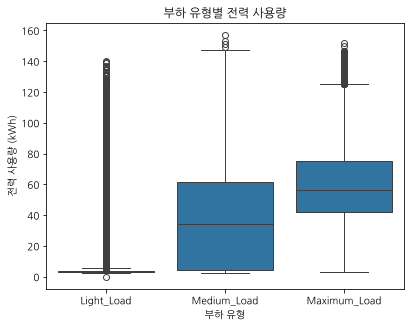

In [ ]:
load_order = ["Light_Load", "Medium_Load", "Maximum_Load"]
sns.boxplot(data=data, x="Load_Type", y="Usage_kWh", order=load_order)
plt.title("부하 유형별 전력 사용량")
plt.xlabel("부하 유형")
plt.ylabel("전력 사용량 (kWh)")
plt.show()

### 4. `crosstab` : 평일·주말의 부하 유형 구성

In [ ]:
display(pd.crosstab(data["WeekStatus"], data["Load_Type"], margins=True))
week_rate = pd.crosstab(data["WeekStatus"], data["Load_Type"], normalize="index") * 100
week_rate.round(2)

Load_Type,Light_Load,Maximum_Load,Medium_Load,All
WeekStatus,,,,
Weekday,11168,5952,7936,25056
Weekend,6904,1320,1760,9984
All,18072,7272,9696,35040


Load_Type,Light_Load,Maximum_Load,Medium_Load
WeekStatus,,,
Weekday,44.57,23.75,31.67
Weekend,69.15,13.22,17.63


### 5. 100% 누적막대 : 평일·주말 구성 그림

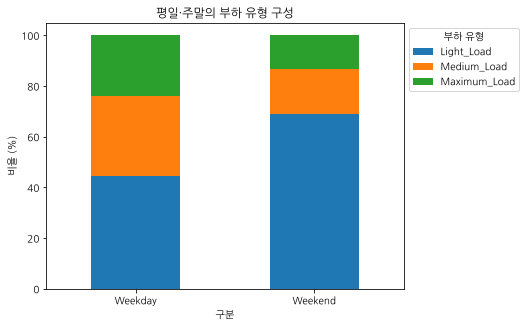

In [ ]:
week_rate[load_order].plot.bar(stacked=True, rot=0)
plt.title("평일·주말의 부하 유형 구성")
plt.xlabel("구분")
plt.ylabel("비율 (%)")
plt.legend(title="부하 유형", bbox_to_anchor=(1, 1), loc="upper left")
plt.show()

### 6. 0/1 평균 = 비율 : 역률 미달

In [ ]:
data["역률미달"] = (data["Lagging_Current_Power_Factor"] < 90).astype(int)
pf = data.groupby("Load_Type")["역률미달"].agg(n="size", 미달건수="sum", 미달비율="mean")
pf["미달비율"] = pf["미달비율"] * 100
pf["미달 기록 중 구성비"] = pf["미달건수"] / pf["미달건수"].sum() * 100
pf.round(2)

,n,미달건수,미달비율,미달 기록 중 구성비
Load_Type,,,,
Light_Load,18072,14332,79.31,74.62
Maximum_Load,7272,2790,38.37,14.53
Medium_Load,9696,2085,21.50,10.86


### 7. `rank` : 요일별 순위

In [ ]:
day = data.groupby("Day_of_week")["Usage_kWh"].agg(n="size", 합계="sum", 평균="mean")
day["합계 순위"] = day["합계"].rank(ascending=False, method="min").astype(int)
day["평균 순위"] = day["평균"].rank(ascending=False, method="min").astype(int)
day.sort_values("평균 순위").round(2)

,n,합계,평균,합계 순위,평균 순위
Day_of_week,,,,,
Thursday,4992,175279.52,35.11,1,1
Tuesday,4992,171862.65,34.43,2,2
Friday,4992,165709.51,33.20,4,3
Monday,5088,168636.34,33.14,3,4
Wednesday,4992,161013.14,32.25,5,5
Saturday,4992,79467.75,15.92,6,6
Sunday,4992,37667.80,7.55,7,7


## 확인문제 정답

### 확인 1. 2번에서 에너지팀 요청(기록 한 건당 평균)에 맞는 값은 단순 평균(35.45 kWh)과 n 가중평균(27.39 kWh) 중 무엇인가?

**답 :** n 가중평균 27.39 kWh다. 기록 한 건당 평균이므로 기록이 많은 Light_Load(18,072건)가 그만큼 더 반영되어야 한다. 이 값은 전체 평균과 같다.

### 확인 2. 4번에서 Light_Load 비중은 평일과 주말에 각각 몇 %인가? 주말에 가벼운 부하의 비중이 늘어나는가?

**답 :** 평일 44.57%, 주말 69.15%로 주말에 비중이 늘어난다. 건수는 주말(6,904건)이 평일(11,168건)보다 적지만, 기록 수가 다르므로 구성은 비율로 비교한다.

### 확인 3. 7번에서 합계 순위와 평균 순위가 서로 다른 요일 두 개는?

**답 :** Monday(합계 3위, 평균 4위)와 Friday(합계 4위, 평균 3위)다. 2018년은 월요일이 53일이라 Monday 기록이 96건 더 많아 합계가 커졌다.

## 개념 확인 정답

### 개념 1. 교차표(`pd.crosstab`)를 사용하는 목적으로 알맞은 것은?

**답 :** ②

교차표는 두 범주형 변수의 조합별 건수를 행 × 열로 정리한 표다. ①은 상관계수, ③은 히스토그램·박스플롯, ④는 `rank()`의 역할이다.

### 개념 2. `pd.crosstab(data["라인"], data["불량여부"])`로 "라인 A에서 생산한 제품 중 불량 비율"을 구할 때 알맞은 옵션은?

**답 :** ①

분모가 라인 A의 전체 생산 건수이므로 행(라인)마다 합이 100%가 되게 나누는 `normalize="index"`를 쓴다. ②는 불량 전체 중 라인 A의 구성비, ③은 전체 건수 대비 비율이다. ④는 합계 행·열을 붙이는 옵션이다.

### 개념 3. 설비 A는 1,000개 중 불량 30개, 설비 B는 200개 중 불량 10개를 만들었다. 옳은 설명은?

**답 :** ②

건수는 발생 규모를, 비율은 집단 안에서의 발생 정도를 보여 준다. 생산량이 다르므로 얼마나 자주 발생했는지는 비율로 비교한다.

### 개념 4. 불량이면 1, 정상이면 0인 열의 값이 [0, 1, 0, 0, 1, 0, 0, 0, 0, 0]이다. 이 열의 평균 0.2가 뜻하는 것은?

**답 :** ②

0/1 변수의 평균은 1의 개수 ÷ 전체 개수, 즉 1의 비율이다. 2 ÷ 10 = 0.2, 불량률 20%다. 불량 건수 2건은 합계(`sum()`)로 구한다.

### 개념 5. 어떤 열에 결측값이 있을 때, 집단별 `size()`와 그 열의 `count()`에 대한 설명으로 옳은 것은?

**답 :** ②

두 값의 차이가 그 집단의 결측 수다. 비율이나 평균의 분모를 정할 때 어느 쪽을 쓰는지 밝혀야 한다. 고유값 개수는 `nunique()`다.

### 개념 6. 설비 X는 기록 10건의 평균 가동률이 80%, 설비 Y는 기록 40건의 평균 가동률이 90%다. 두 설비 전체 기록 50건의 평균 가동률은?

**답 :** ③

(10 × 80 + 40 × 90) ÷ 50 = 4,400 ÷ 50 = 88%다. ① 85%는 두 평균의 단순 평균으로, 기록이 많은 설비 Y의 비중을 줄여 반영한 값이다.

### 개념 7. `pivot_table()`을 사용하는 목적으로 알맞은 것은?

**답 :** ②

`groupby()`에 기준을 두 개 주면 조합 하나가 한 행인 긴 표가 나온다. 피벗표는 같은 결과를 행 × 열의 넓은 표로 펼쳐 비교하기 쉽게 한다. ①은 교차표, ③은 상관계수, ④는 `rank()`의 역할이다.

### 개념 8. 라인별 불량 건수 [5, 3, 3, 1]에 `rank(ascending=False, method="min")`을 적용한 결과는?

**답 :** ②

`ascending=False`이므로 큰 값이 1위다. 동점인 두 3은 가장 작은 순위인 2위를 함께 받고, 다음 값은 4위가 된다. ③은 `method="dense"`, ④는 기본값 `method="average"`의 결과다.